# Parte práctica · Semana 3 · Fase 4

## Visualización y comunicación de resultados: de la pregunta a la figura

**MCDI500 · Programación para la Ciencia de Datos**
**Magíster en Ciencia de Datos e Inteligencia Artificial · Universidad Andrés Bello**

---

En las tres semanas anteriores el objeto de trabajo fueron los datos y el código. En la
Fase 4 el objeto es **el lector**: qué necesita saber, en qué orden, con qué evidencia y con
qué advertencias.

Este cuaderno no es un catálogo de gráficos. Recorre el camino que hará su equipo en el
proyecto final:

1. Partir de una **pregunta** declarada en la Fase 1.
2. Construir una **copia interpretable** de los datos procesados, con sus unidades originales.
3. Elegir el gráfico según lo que la pregunta compara, no según el gusto.
4. Construir la figura paso a paso, hasta que **su título diga el hallazgo**.
5. Revisar que no distorsione y que no confunda asociación con causa.
6. Ordenar las figuras en un **relato** y exportarlas para el informe y el video.

**Caso de trabajo.** El mismo de todo el módulo: el *Stroke Prediction Dataset*
(fedesoriano, Kaggle), 5.110 personas y 12 variables. Ustedes aplican lo mismo a su propio
conjunto en el proyecto.

**Cómo usarlo.** Ejecuten las celdas en orden. Al final hay ejercicios marcados con `TODO`.

---
## 1. Preparación

Se usan solo las librerías que ya están en el entorno del proyecto: NumPy, pandas y
matplotlib. No hace falta instalar nada nuevo para visualizar bien.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SEMILLA = 42
np.random.seed(SEMILLA)

print("pandas     :", pd.__version__)
print("NumPy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)

pandas     : 3.0.5
NumPy      : 2.5.3
matplotlib : 3.11.2


### Carga del conjunto real

El cuaderno lee el archivo de la carpeta `data/` que acompaña a esta práctica. Si no lo
encuentra, se detiene y dice dónde ponerlo: una figura hecha con datos inventados no
responde ninguna pregunta.

In [2]:
RUTA = Path("data") / "healthcare-dataset-stroke-data.csv"

if not RUTA.exists():
    raise FileNotFoundError(
        f"No se encontró {RUTA}. Descarguen el conjunto desde "
        "https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset "
        "y déjenlo en la carpeta data/ junto a este cuaderno."
    )

datos = pd.read_csv(RUTA)
print(f"{datos.shape[0]} filas x {datos.shape[1]} columnas")
datos.head()

5110 filas x 12 columnas


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


---
## 2. Primero la pregunta, después el gráfico

El error más común de la Fase 4 es abrir el cuaderno y empezar a graficar todas las
variables. El resultado son veinte figuras que no dicen nada. El orden correcto es el
inverso: **cada figura existe porque responde una pregunta**.

En el caso stroke, la Fase 1 declaró este objetivo general: *caracterizar los factores
asociados al accidente cerebrovascular*. De él salen preguntas concretas, y de cada
pregunta sale qué se compara y, por lo tanto, qué gráfico conviene.

In [3]:
plan = pd.DataFrame([
    {"pregunta": "¿Qué tan frecuente es el ACV en el conjunto?",
     "compara": "una proporción contra su complemento", "grafico": "barra horizontal"},
    {"pregunta": "¿Cómo cambia el riesgo con la edad?",
     "compara": "una tasa entre grupos ordenados", "grafico": "barras con intervalo"},
    {"pregunta": "¿La hipertensión se asocia al ACV a igual edad?",
     "compara": "una tasa entre grupos, dentro de estratos", "grafico": "barras agrupadas"},
    {"pregunta": "¿Cómo se distribuye la glucosa en quienes tuvieron ACV?",
     "compara": "dos distribuciones", "grafico": "histogramas superpuestos o cajas"},
    {"pregunta": "¿Se relacionan la edad y el IMC?",
     "compara": "dos variables continuas", "grafico": "dispersión"},
])
plan

,pregunta,compara,grafico
0,¿Qué tan frecuente es el ACV en el conjunto?,una proporción contra su complemento,barra horizontal
1,¿Cómo cambia el riesgo con la edad?,una tasa entre grupos ordenados,barras con intervalo
2,¿La hipertensión se asocia al ACV a igual edad?,"una tasa entre grupos, dentro de estratos",barras agrupadas
3,¿Cómo se distribuye la glucosa en quienes tuvi...,dos distribuciones,histogramas superpuestos o cajas
4,¿Se relacionan la edad y el IMC?,dos variables continuas,dispersión


### Por qué el tipo de gráfico no es una cuestión de gusto

Cleveland y McGill (1984) midieron con qué precisión las personas comparan cantidades
según cómo se codifican. El orden, de más a menos preciso, es:

1. **Posición sobre una escala común** (barras alineadas, puntos)
2. Longitud
3. Ángulo y pendiente
4. Área
5. Color y saturación

Por eso una barra casi siempre le gana a un gráfico de torta: comparar longitudes sobre un
eje común es más preciso que comparar ángulos. La siguiente celda lo muestra con los tipos
de trabajo del conjunto.

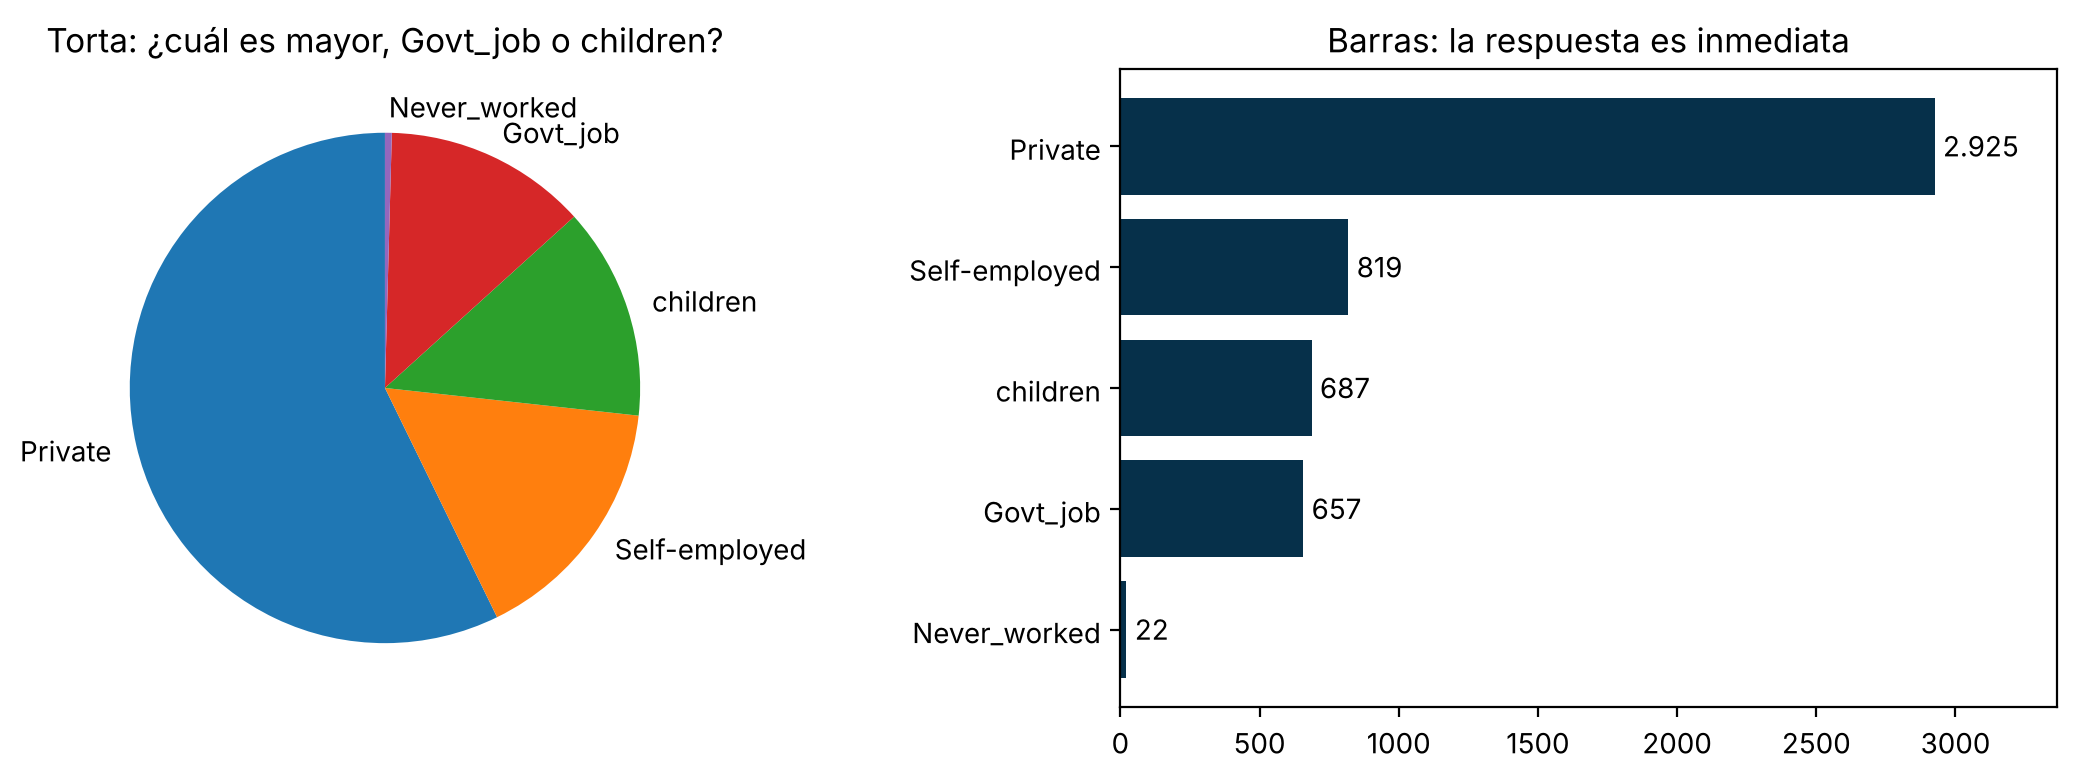

In [4]:
trabajo = datos["work_type"].value_counts()

fig, (torta, barras) = plt.subplots(1, 2, figsize=(11, 4))
torta.pie(trabajo.values, labels=trabajo.index, startangle=90)
torta.set_title("Torta: ¿cuál es mayor, Govt_job o children?")
barras.barh(trabajo.index[::-1], trabajo.values[::-1], color="#06304A")
barras.set_title("Barras: la respuesta es inmediata")
for y, valor in enumerate(trabajo.values[::-1]):
    barras.text(valor + 30, y, f"{valor:,}".replace(",", "."), va="center")
barras.set_xlim(0, trabajo.max() * 1.15)
plt.tight_layout()
plt.show()

En la torta, `Govt_job` (657) y `children` (687) parecen iguales. En las barras, la
diferencia se ve y además se puede leer. Regla práctica: **usen torta solo con dos o tres
categorías y cuando la idea sea parte de un todo**. En cualquier otro caso, barras.

---
## 3. La copia interpretable

En la Fase 3 las variables continuas quedaron **escaladas**: media 0 y desviación 1. Eso
sirve para algoritmos, pero no para personas. Un eje que dice «edad = 1,5» no se entiende.

Para comunicar, la Fase 4 construye una **copia** con las unidades originales. No se vuelve
a procesar: se aplica la inversa exacta del escalamiento con los parámetros que aprendió la
Fase 3, que están guardados en `parametros_f3.csv`.

$$z = \frac{x - \mu}{\sigma} \quad\Longrightarrow\quad x = z \cdot \sigma + \mu$$

La siguiente celda simula lo que entrega la Fase 3 y lo revierte.

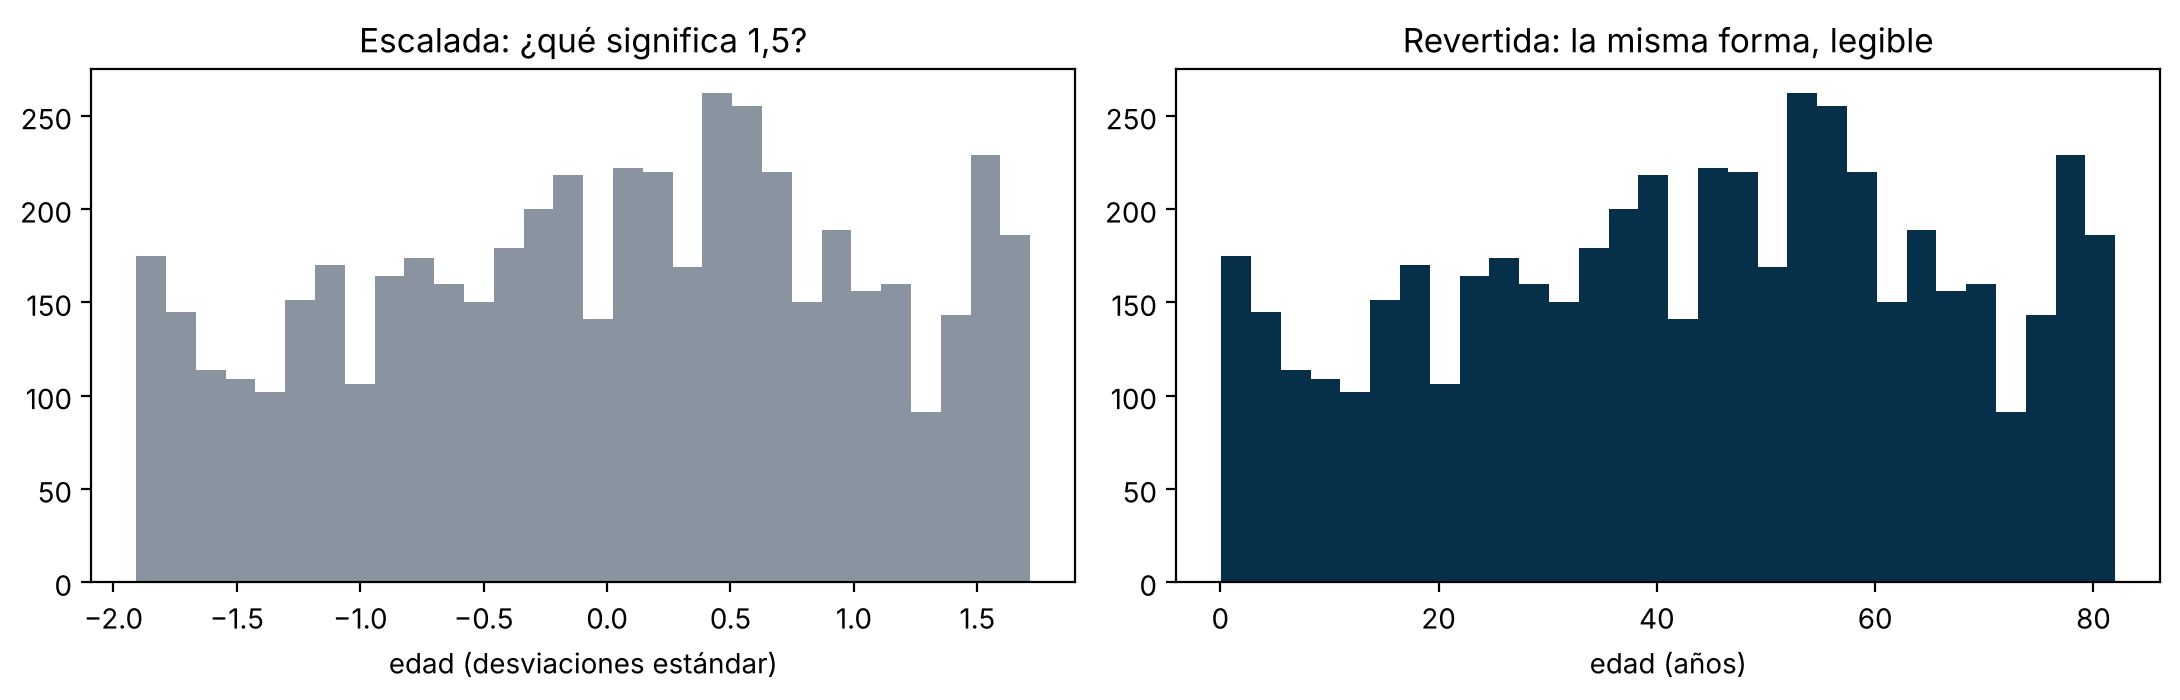

La inversa reproduce exactamente las edades originales.


In [5]:
# Lo que hizo la Fase 3: aprender media y desviación, y escalar
media_edad = datos["age"].mean()
desviacion_edad = datos["age"].std()
edad_escalada = (datos["age"] - media_edad) / desviacion_edad

# Lo que hace la Fase 4: aplicar la inversa con esos mismos parámetros
edad_revertida = edad_escalada * desviacion_edad + media_edad

fig, (escalada, original) = plt.subplots(1, 2, figsize=(11, 3.6))
escalada.hist(edad_escalada, bins=30, color="#8A94A0")
escalada.set_title("Escalada: ¿qué significa 1,5?")
escalada.set_xlabel("edad (desviaciones estándar)")
original.hist(edad_revertida, bins=30, color="#06304A")
original.set_title("Revertida: la misma forma, legible")
original.set_xlabel("edad (años)")
plt.tight_layout()
plt.show()

assert np.allclose(edad_revertida, datos["age"]), "La inversa no reproduce el original"
print("La inversa reproduce exactamente las edades originales.")

**Dos advertencias.** La primera: la inversa usa los parámetros **del entrenamiento**, no
se recalculan. La segunda: la copia es solo para comunicar. Los artefactos de la Fase 3 no
se modifican, porque cualquier análisis posterior debe partir de ellos.

En el proyecto modelo esta operación está en `src/comunicacion.py`, con la función
`copia_interpretable`, que además vuelve a juntar las columnas 0/1 de cada variable
categórica en una sola columna legible.

---
## 4. Anatomía de una figura que comunica

Se construye una sola figura en cinco pasos. La pregunta es: **¿cómo cambia la tasa de ACV
con la edad?**

### Paso 1 · El gráfico por defecto

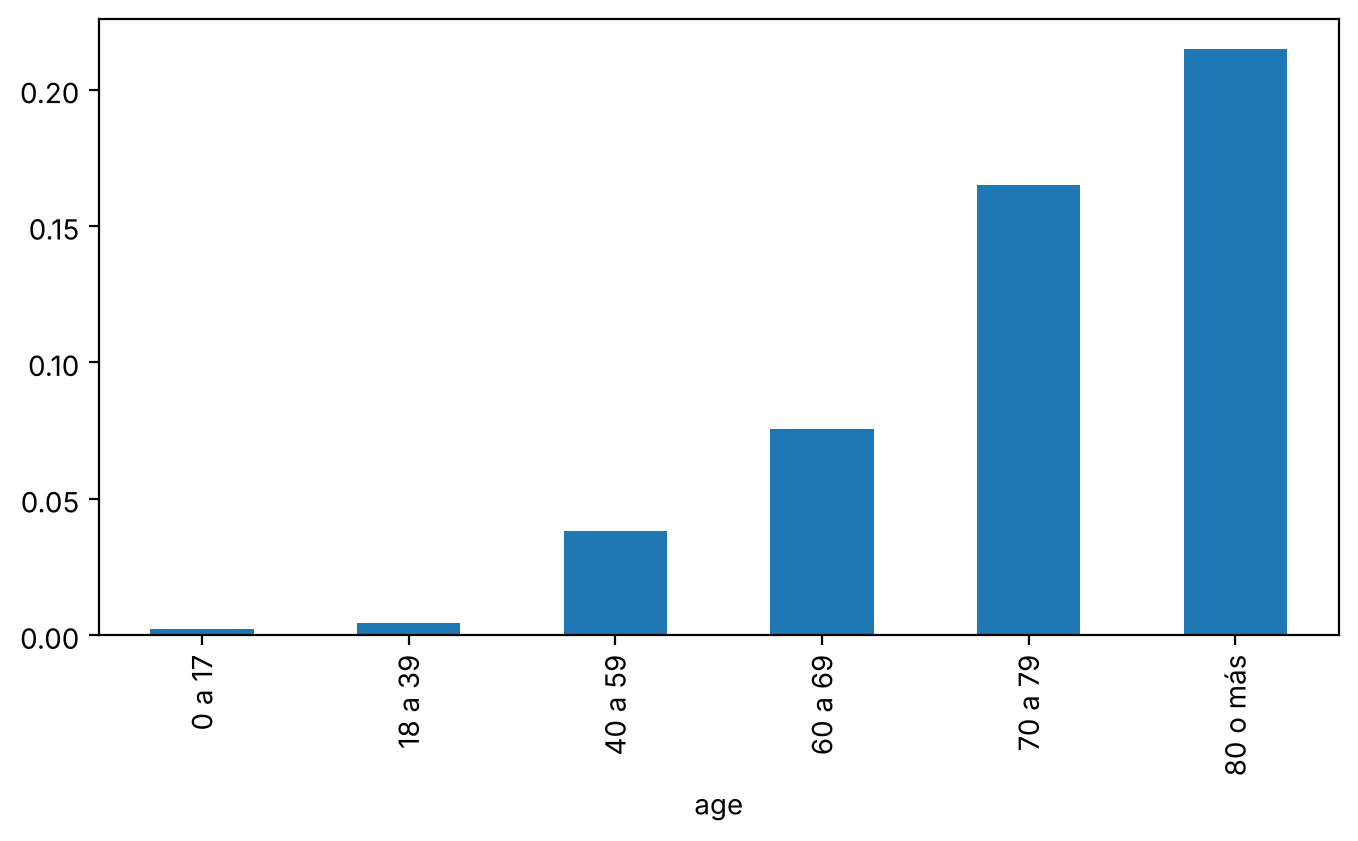

In [6]:
tramos = pd.cut(datos["age"], [0, 18, 40, 60, 70, 80, 120], right=False,
                labels=["0 a 17", "18 a 39", "40 a 59", "60 a 69", "70 a 79", "80 o más"])
tasa = datos.groupby(tramos, observed=True)["stroke"].mean()
n = datos.groupby(tramos, observed=True).size()

fig, ax = plt.subplots(figsize=(8, 4))
tasa.plot(kind="bar", ax=ax)
plt.show()

Es correcto, pero no comunica: el título no existe, el eje está en proporciones, las
etiquetas están giradas y nada indica qué mirar.

### Paso 2 · Ejes legibles y etiquetas en horizontal

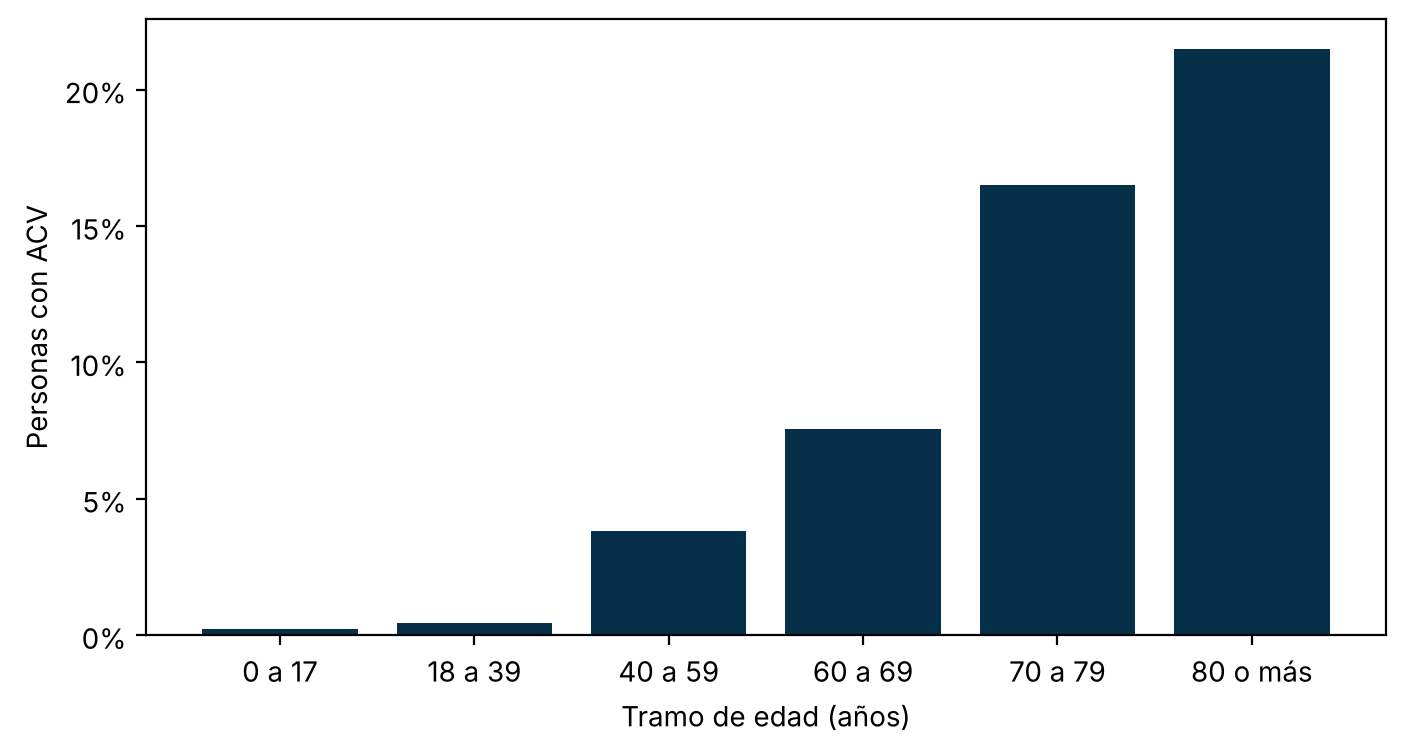

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tasa.index.astype(str), tasa.values, color="#06304A")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Tramo de edad (años)")
ax.set_ylabel("Personas con ACV")
plt.show()

### Paso 3 · El título dice el hallazgo

Un título descriptivo («Tasa de ACV por tramo de edad») obliga al lector a descubrir solo
lo que hay que ver. Un título que comunica lo dice: el lector lo lee, mira la figura y la
confirma.

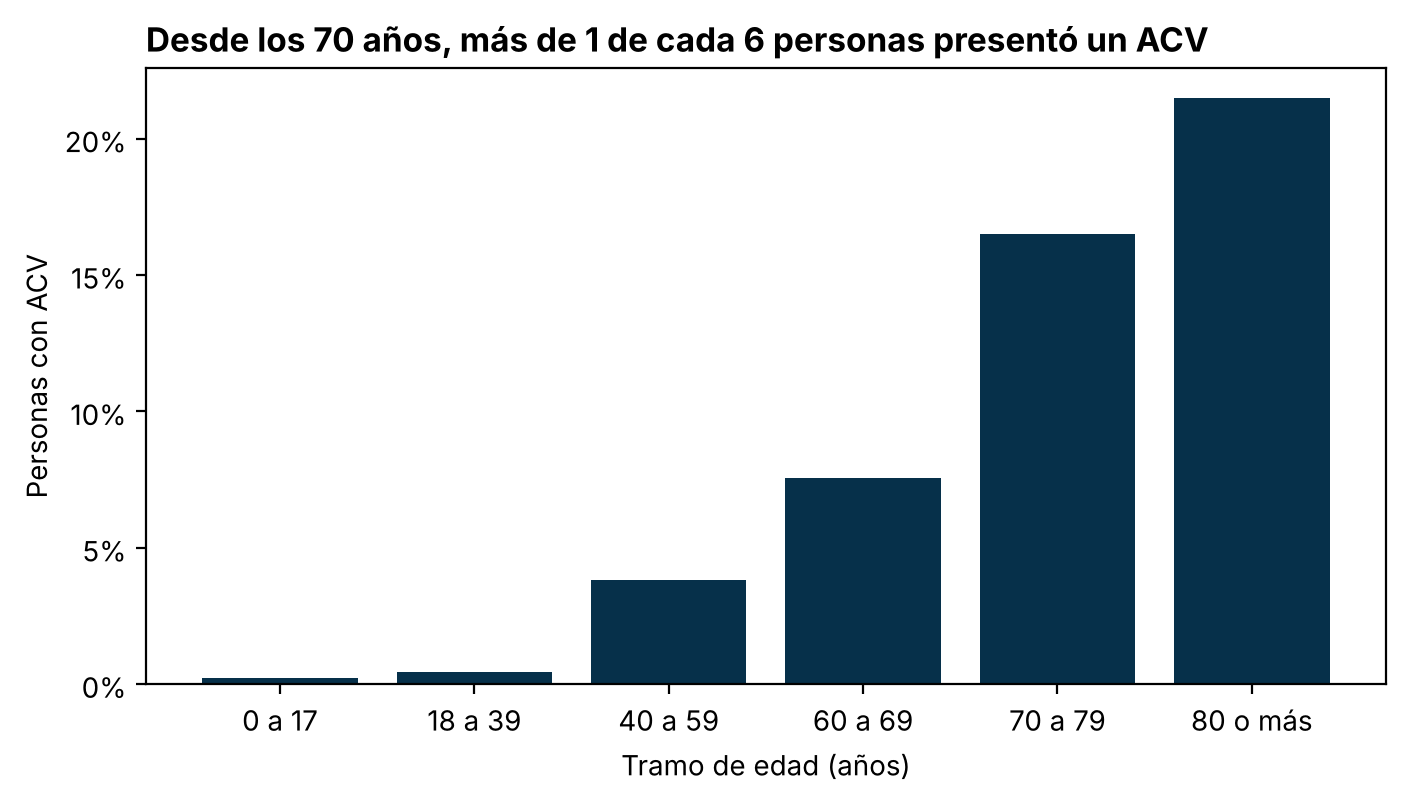

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tasa.index.astype(str), tasa.values, color="#06304A")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Tramo de edad (años)")
ax.set_ylabel("Personas con ACV")
ax.set_title("Desde los 70 años, más de 1 de cada 6 personas presentó un ACV",
             loc="left", fontweight="bold")
plt.show()

### Paso 4 · El color con función

El color no decora: señala. Se pinta en granate solo lo que el título menciona y el resto
queda en un tono de contexto. Se agrega además una línea de referencia con el promedio,
para que «alto» y «bajo» tengan contra qué compararse.

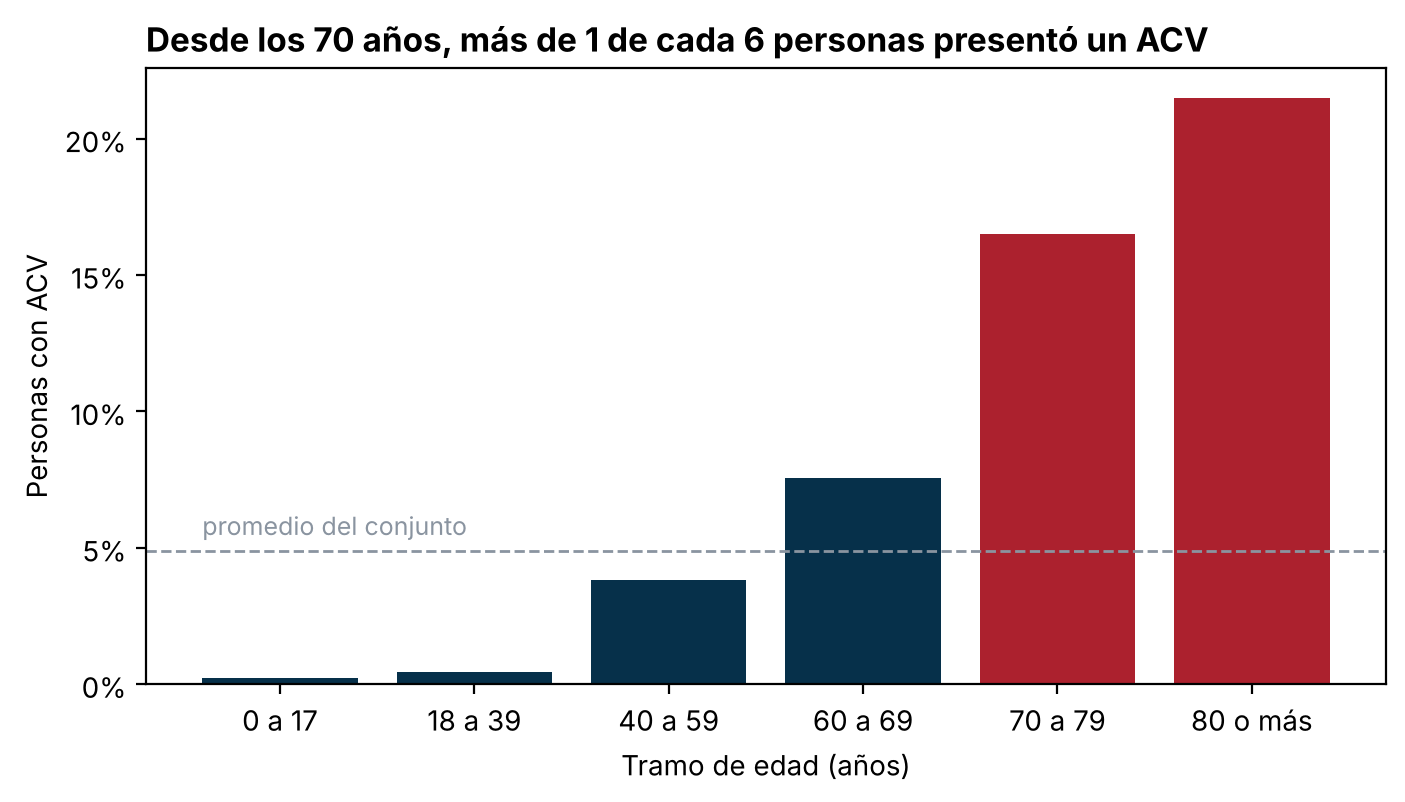

In [9]:
GRANATE, AZUL, GRIS = "#AC212E", "#06304A", "#8A94A0"
colores = [GRANATE if t >= 0.15 else AZUL for t in tasa.values]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tasa.index.astype(str), tasa.values, color=colores)
ax.axhline(datos["stroke"].mean(), color=GRIS, ls="--", lw=1)
ax.text(-0.4, datos["stroke"].mean() + 0.006, "promedio del conjunto", color=GRIS, fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Tramo de edad (años)")
ax.set_ylabel("Personas con ACV")
ax.set_title("Desde los 70 años, más de 1 de cada 6 personas presentó un ACV",
             loc="left", fontweight="bold")
plt.show()

### Paso 5 · La incertidumbre y la fuente

Una tasa calculada sobre 186 personas no vale lo mismo que una calculada sobre 1.564. Se
agrega el tamaño de cada grupo y su **intervalo de confianza al 95 %** (método de Wilson,
que no da límites negativos con proporciones pequeñas), y al pie la fuente.

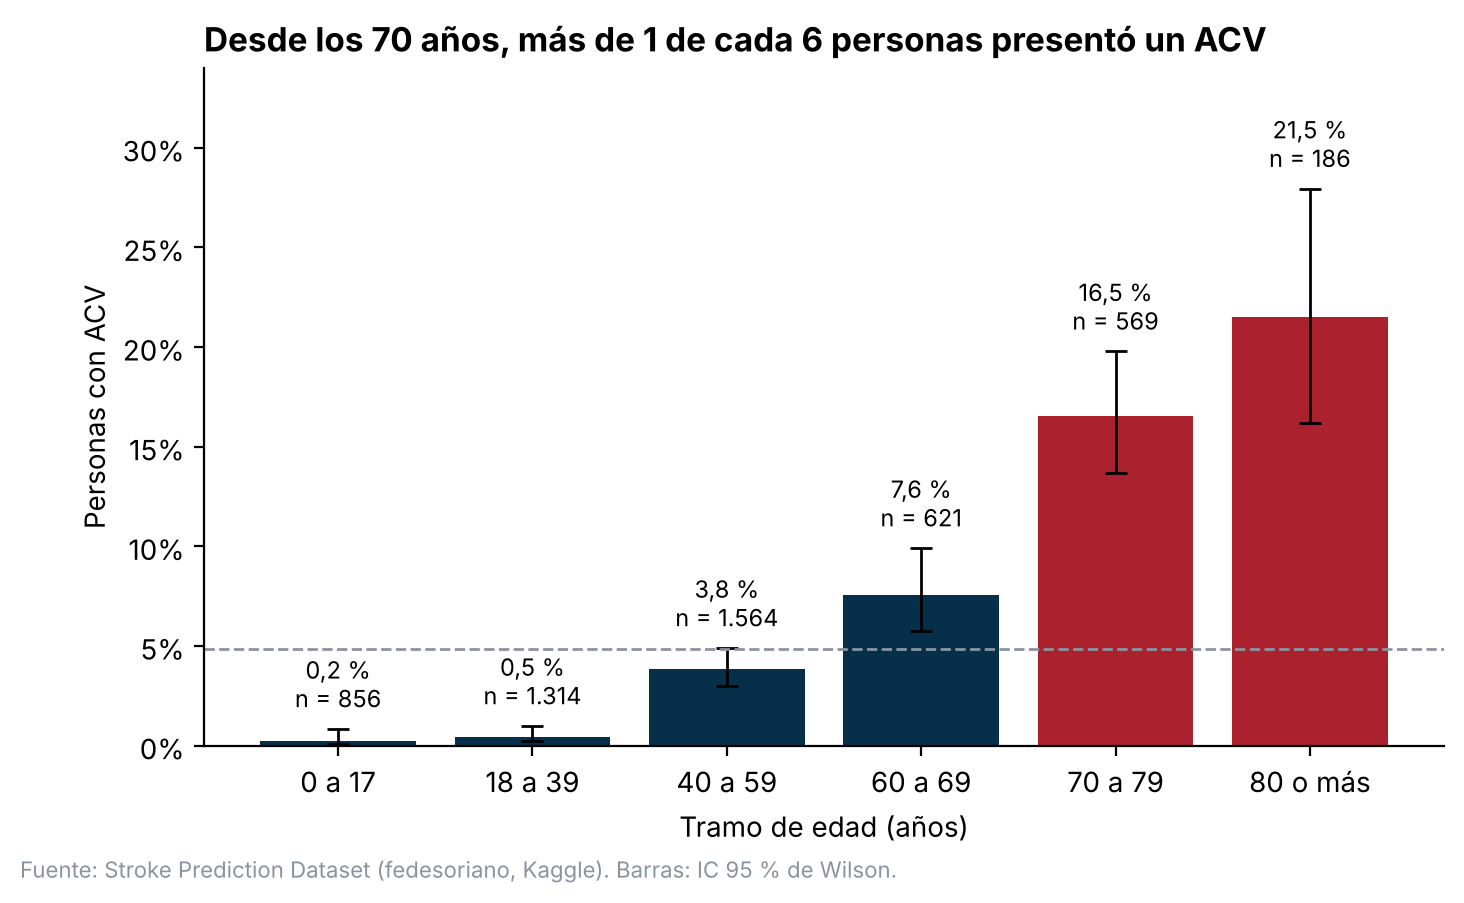

In [10]:
def intervalo_wilson(exitos, total, z=1.96):
    """Intervalo de confianza de Wilson para una proporción."""
    p = exitos / total
    denominador = 1 + z ** 2 / total
    centro = (p + z ** 2 / (2 * total)) / denominador
    margen = z * np.sqrt(p * (1 - p) / total + z ** 2 / (4 * total ** 2)) / denominador
    return max(0.0, centro - margen), min(1.0, centro + margen)


casos = datos.groupby(tramos, observed=True)["stroke"].sum()
limites = [intervalo_wilson(c, t) for c, t in zip(casos, n)]
error = np.array([[t - li for t, (li, _) in zip(tasa, limites)],
                  [ls - t for t, (_, ls) in zip(tasa, limites)]])

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.bar(tasa.index.astype(str), tasa.values, color=colores, yerr=error,
       error_kw={"capsize": 4, "lw": 1})
for x, (t, total) in enumerate(zip(tasa.values, n.values)):
    ax.text(x, limites[x][1] + 0.008, f"{t * 100:.1f} %\nn = {total:,}".replace(",", "X").replace(".", ",").replace("X", "."),
            ha="center", va="bottom", fontsize=8.5)
ax.axhline(datos["stroke"].mean(), color=GRIS, ls="--", lw=1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.34)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("Tramo de edad (años)")
ax.set_ylabel("Personas con ACV")
ax.set_title("Desde los 70 años, más de 1 de cada 6 personas presentó un ACV",
             loc="left", fontweight="bold")
fig.text(0.01, -0.04, "Fuente: Stroke Prediction Dataset (fedesoriano, Kaggle). Barras: IC 95 % de Wilson.",
         fontsize=8, color=GRIS)
plt.show()

### Lista de control de una figura

| Elemento | Pregunta que se hace |
|---|---|
| Título | ¿Dice el hallazgo y no el tipo de gráfico? |
| Ejes | ¿Tienen nombre y unidades, y se leen sin girar la cabeza? |
| Escala | ¿Las barras empiezan en cero? |
| Color | ¿Señala lo importante o solo decora? |
| Incertidumbre | ¿Se ve el tamaño de cada grupo o su intervalo? |
| Fuente | ¿Dice de dónde vienen los datos? |
| Pregunta | ¿Responde una pregunta u objetivo de la Fase 1? |

---
## 5. El gráfico según lo que se compara

No hay un gráfico para cada variable, hay un gráfico para cada **relación**. Cinco
relaciones cubren casi todo lo que necesitan en el proyecto.

### 5.1 Comparar grupos: barras

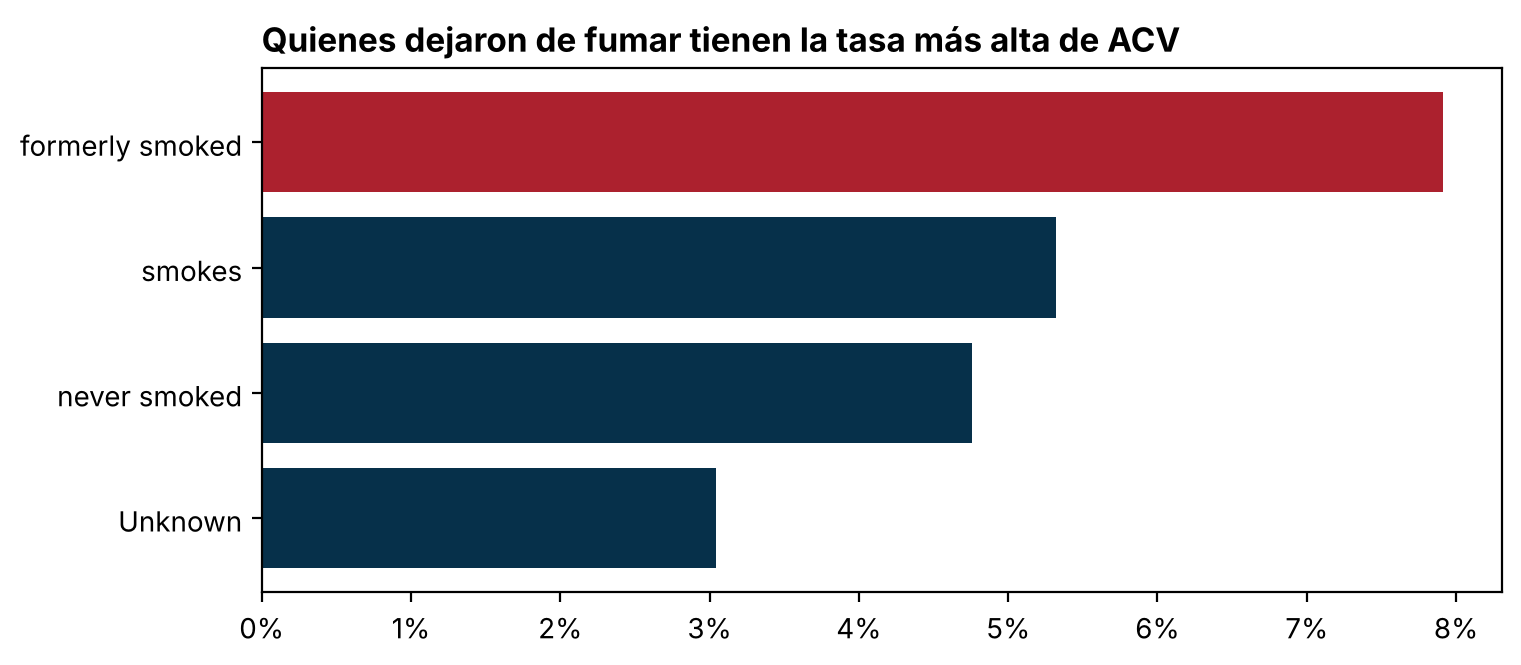

In [11]:
por_tabaquismo = datos.groupby("smoking_status")["stroke"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(por_tabaquismo.index, por_tabaquismo.values,
        color=[GRANATE if i == "formerly smoked" else AZUL for i in por_tabaquismo.index])
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("Quienes dejaron de fumar tienen la tasa más alta de ACV", loc="left", fontweight="bold")
plt.show()

Las categorías se **ordenan por el valor**, no alfabéticamente: el ojo recorre la figura de
menor a mayor sin esfuerzo. Y una advertencia que retoma la sección 7: quienes dejaron de
fumar suelen ser mayores, así que esta diferencia puede deberse a la edad.

### 5.2 Comparar distribuciones: histogramas y cajas

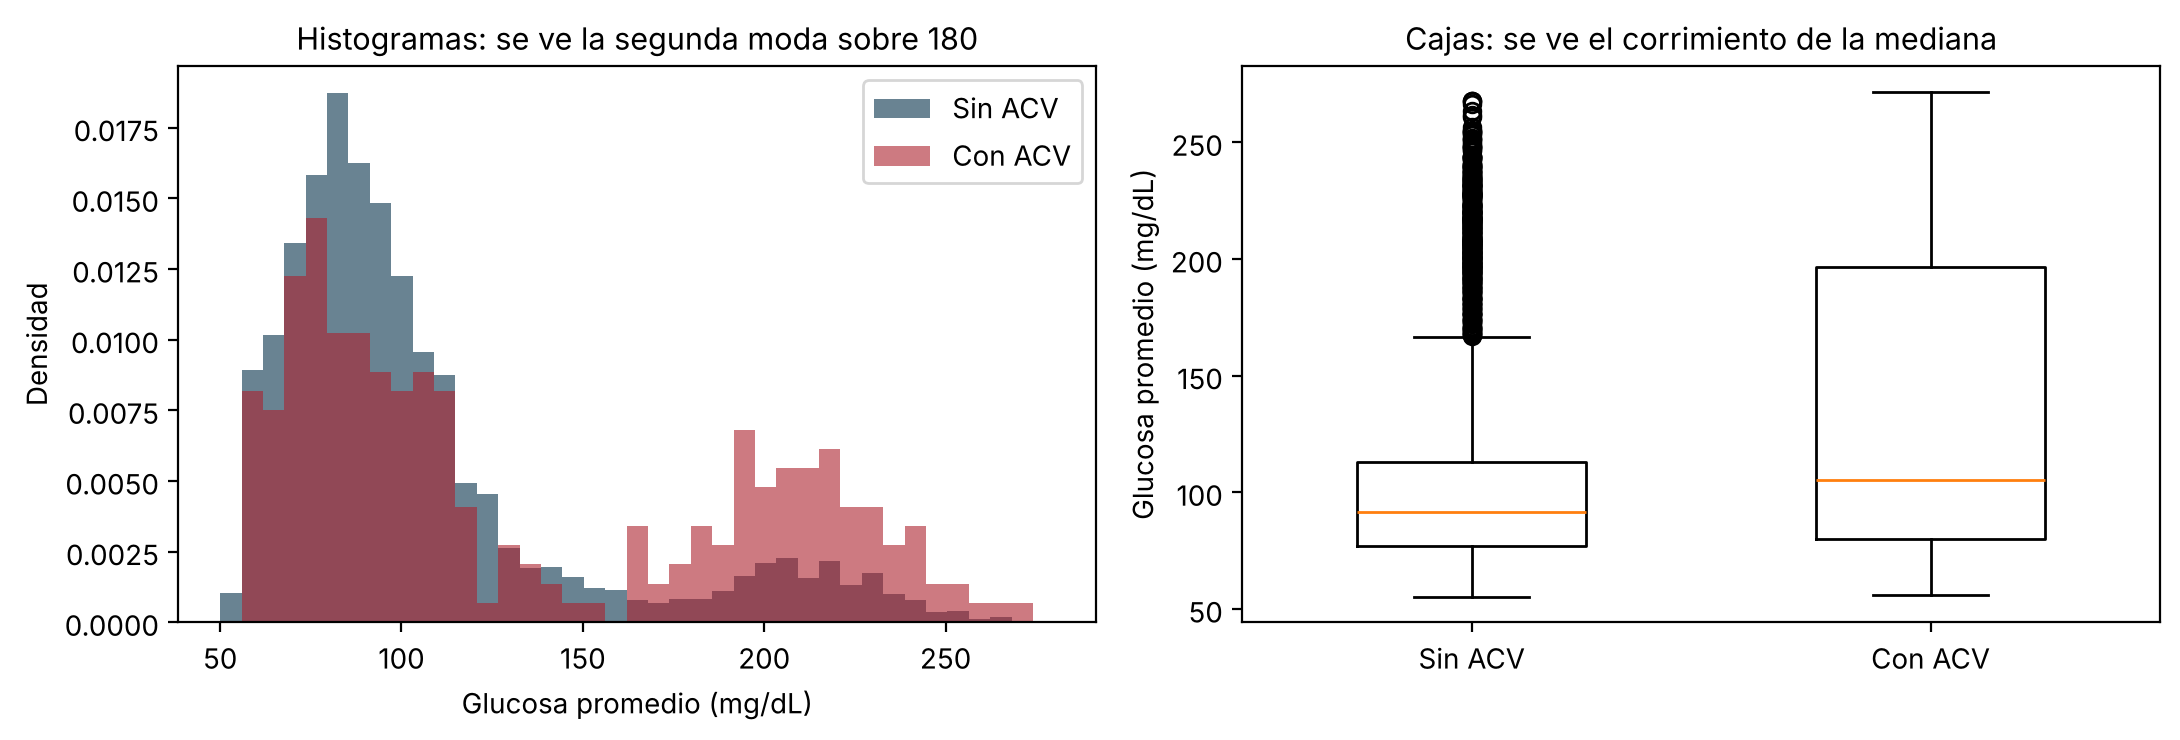

Mediana sin ACV: 91,5 mg/dL · con ACV: 105,2 mg/dL


In [12]:
sin_acv = datos.loc[datos["stroke"] == 0, "avg_glucose_level"]
con_acv = datos.loc[datos["stroke"] == 1, "avg_glucose_level"]

fig, (hist, caja) = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(50, 280, 40)
hist.hist(sin_acv, bins=bins, density=True, alpha=0.6, color=AZUL, label="Sin ACV")
hist.hist(con_acv, bins=bins, density=True, alpha=0.6, color=GRANATE, label="Con ACV")
hist.set_xlabel("Glucosa promedio (mg/dL)")
hist.set_ylabel("Densidad")
hist.legend()
hist.set_title("Histogramas: se ve la segunda moda sobre 180", fontsize=11)
caja.boxplot([sin_acv, con_acv], tick_labels=["Sin ACV", "Con ACV"], widths=0.5)
caja.set_ylabel("Glucosa promedio (mg/dL)")
caja.set_title("Cajas: se ve el corrimiento de la mediana", fontsize=11)
plt.tight_layout()
plt.show()

print(f"Mediana sin ACV: {sin_acv.median():.1f} mg/dL · con ACV: {con_acv.median():.1f} mg/dL".replace(".", ","))

Con grupos de tamaño muy distinto (4.861 frente a 249) se usa `density=True`: compara la
**forma** y no la cantidad. Sin eso, el histograma del grupo pequeño quedaría aplastado y
parecería irrelevante.

### 5.3 Relacionar dos continuas: dispersión

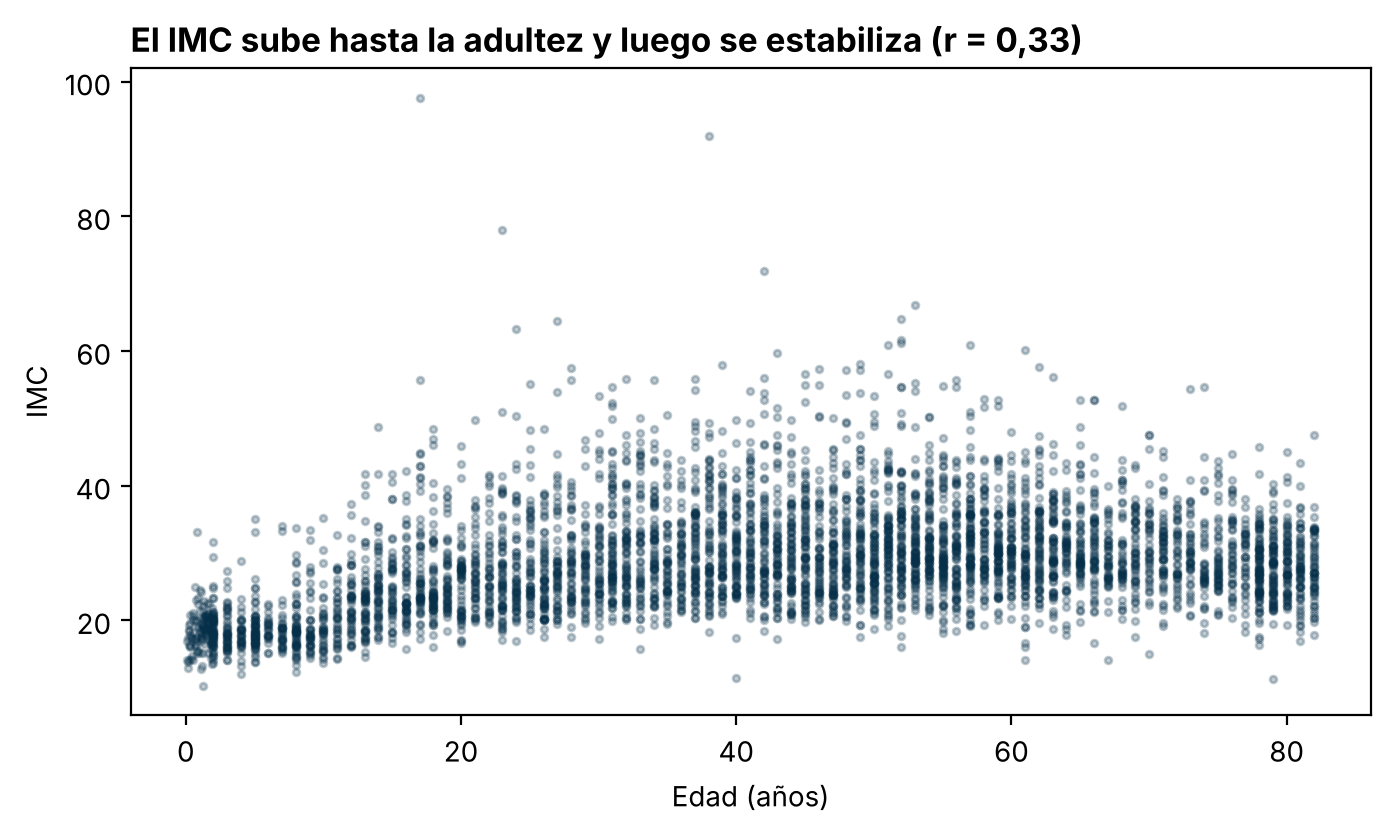

In [13]:
muestra = datos.dropna(subset=["bmi"])

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(muestra["age"], muestra["bmi"], s=6, alpha=0.25, color=AZUL)
ax.set_xlabel("Edad (años)")
ax.set_ylabel("IMC")
correlacion = muestra[["age", "bmi"]].corr().iloc[0, 1]
ax.set_title(f"El IMC sube hasta la adultez y luego se estabiliza (r = {correlacion:.2f})".replace(".", ","),
             loc="left", fontweight="bold")
plt.show()

Con miles de puntos, la transparencia (`alpha`) evita que la nube se vuelva una mancha. Y
el coeficiente de correlación lineal resume mal una relación que no es lineal, como esta:
la figura muestra lo que el número esconde.

### 5.4 Composición: barras apiladas al 100 %

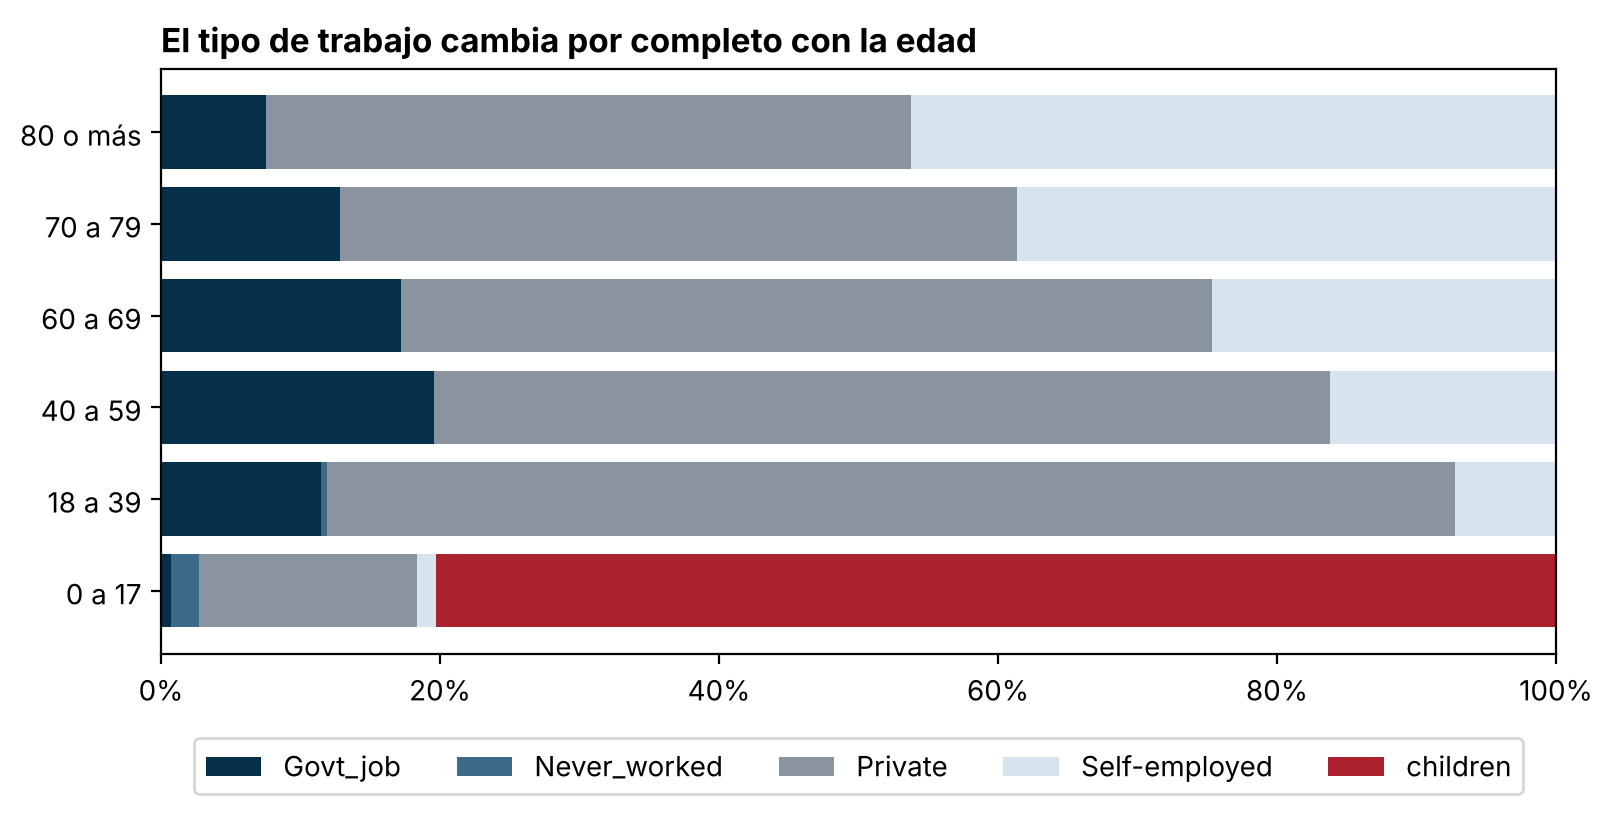

In [14]:
composicion = pd.crosstab(tramos, datos["work_type"], normalize="index")

fig, ax = plt.subplots(figsize=(9, 3.8))
izquierda = np.zeros(len(composicion))
paleta = ["#06304A", "#3E6A8A", "#8A94A0", "#D7E3EE", "#AC212E"]
for color, categoria in zip(paleta, composicion.columns):
    ax.barh(composicion.index.astype(str), composicion[categoria], left=izquierda, color=color, label=categoria)
    izquierda += composicion[categoria].to_numpy()
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend(ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("El tipo de trabajo cambia por completo con la edad", loc="left", fontweight="bold")
plt.show()

### 5.5 Evolución en el tiempo

El caso stroke **no tiene variable temporal**, y la Fase 1 lo declaró como limitación. Si
su conjunto la tiene, el gráfico de líneas es la elección por defecto, con el tiempo en el
eje horizontal. Si no la tiene, no inventen una: declárenlo.

### 5.6 seaborn dibuja, Matplotlib termina

seaborn resuelve en una línea el gráfico estadístico: agrupa, calcula la media y su
intervalo de confianza. Lo que comunica, el título con el hallazgo, el formato del eje y la
fuente, se agrega después con Matplotlib sobre el mismo eje.

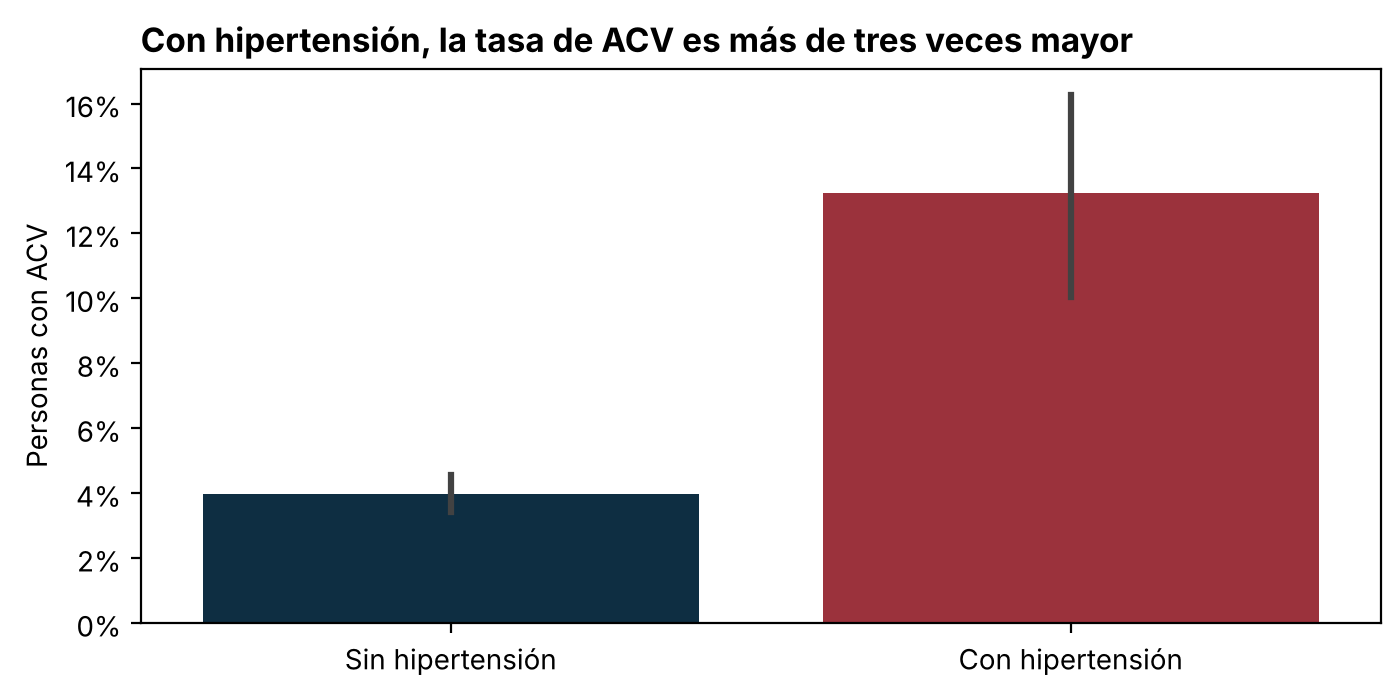

In [15]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.barplot(data=datos, x="hypertension", y="stroke", hue="hypertension",
            palette=[AZUL, GRANATE], legend=False, errorbar=("ci", 95), seed=SEMILLA, ax=ax)
ax.set_xticks([0, 1], ["Sin hipertensión", "Con hipertensión"])
ax.set_xlabel("")
ax.set_ylabel("Personas con ACV")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("Con hipertensión, la tasa de ACV es más de tres veces mayor", loc="left", fontweight="bold")
plt.show()

El intervalo que dibuja seaborn se calcula por remuestreo (*bootstrap*); por eso se fija
la semilla con `seed`, para que la figura sea la misma en cada ejecución.

---
## 6. Una figura por objetivo

En el informe no caben veinte figuras: caben las que responden los objetivos. La regla es
simple de enunciar y exigente de cumplir:

> Si una figura no responde algún objetivo, no va al informe.
> Si un objetivo no tiene figura que lo responda, el trabajo está incompleto.

La siguiente tabla es la que su equipo debe construir para el proyecto.

In [16]:
vinculacion = pd.DataFrame([
    {"objetivo": "Caracterizar la frecuencia del evento", "figura": "Figura 1",
     "hallazgo": "4,9 % de las personas presentó ACV"},
    {"objetivo": "Identificar el factor con mayor asociación", "figura": "Figura 2",
     "hallazgo": "La tasa pasa de 0,2 % a 21,5 % entre el tramo más joven y el mayor"},
    {"objetivo": "Evaluar factores clínicos controlando la edad", "figura": "Figura 3",
     "hallazgo": "La hipertensión eleva la tasa en ambos grupos de edad"},
])
vinculacion

,objetivo,figura,hallazgo
0,Caracterizar la frecuencia del evento,Figura 1,"4,9 % de las personas presentó ACV"
1,Identificar el factor con mayor asociación,Figura 2,"La tasa pasa de 0,2 % a 21,5 % entre el tramo ..."
2,Evaluar factores clínicos controlando la edad,Figura 3,La hipertensión eleva la tasa en ambos grupos ...


---
## 7. Asociación no es causalidad

Esta sección es la que más distingue un informe de posgrado de uno básico. Con datos
observacionales, una diferencia entre grupos puede deberse a una **tercera variable** que
afecta a ambos. Se llama variable de confusión.

### 7.1 Un ejemplo que engaña: el estado civil

In [17]:
bruto = datos.groupby("ever_married")["stroke"].mean()
print("Tasa de ACV sin separar por edad")
print(f"  Alguna vez casado: {bruto['Yes'] * 100:.1f} %".replace(".", ","))
print(f"  Nunca casado     : {bruto['No'] * 100:.1f} %".replace(".", ","))
print(f"  Razón            : {bruto['Yes'] / bruto['No']:.1f} veces".replace(".", ","))
print("\nMediana de edad:", datos.groupby("ever_married")["age"].median().to_dict())

Tasa de ACV sin separar por edad
  Alguna vez casado: 6,6 %
  Nunca casado     : 1,7 %
  Razón            : 4,0 veces

Mediana de edad: {'No': 18.0, 'Yes': 54.0}


¿Casarse cuadruplica el riesgo de ACV? No. Las personas que nunca se han casado incluyen a
todos los menores de edad, y los menores casi no presentan ACV. La diferencia se explica
por la edad. Para comprobarlo se **estratifica**: se compara dentro de grupos de edad
similar.

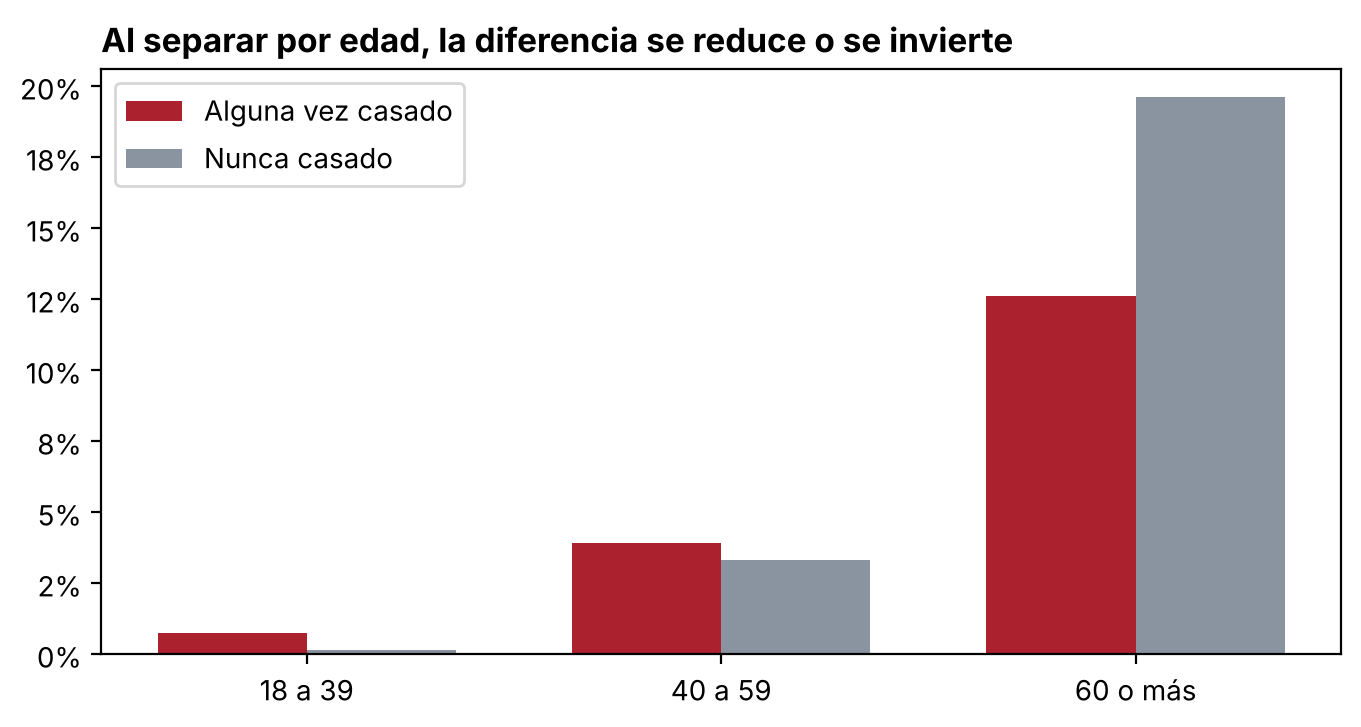

In [18]:
adultos = datos[datos["age"] >= 18].copy()
adultos["tramo"] = pd.cut(adultos["age"], [18, 40, 60, 120], right=False,
                          labels=["18 a 39", "40 a 59", "60 o más"])
estratificado = adultos.groupby(["tramo", "ever_married"], observed=True)["stroke"].mean().unstack()

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(estratificado))
ax.bar(x - 0.18, estratificado["Yes"], width=0.36, color=GRANATE, label="Alguna vez casado")
ax.bar(x + 0.18, estratificado["No"], width=0.36, color=GRIS, label="Nunca casado")
ax.set_xticks(x, estratificado.index.astype(str))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend(loc="upper left")
ax.set_title("Al separar por edad, la diferencia se reduce o se invierte", loc="left", fontweight="bold")
plt.show()

Entre los 40 y 59 años las tasas son casi iguales, y desde los 60 se invierten. La
asociación bruta era **espuria**. Antes de escribir «X se asocia con Y» en el informe,
pregúntense qué variable podría explicar a ambas, y estratifiquen por ella.

### 7.2 Cuando la asociación resiste el control

In [19]:
datos["grupo_edad"] = np.where(datos["age"] >= 60, "60 o más", "menos de 60")
hipertension = datos.groupby(["grupo_edad", "hypertension"])["stroke"].mean().unstack()
hipertension.columns = ["Sin hipertensión", "Con hipertensión"]
(hipertension * 100).round(1)

,Sin hipertensión,Con hipertensión
grupo_edad,,
60 o más,11.9,17.9
menos de 60,1.6,6.4


Aquí la diferencia **persiste** dentro de cada grupo de edad. Eso fortalece la asociación,
pero no la convierte en causa: puede haber otras variables de confusión no medidas. La
redacción correcta en el informe es «se asocia con», nunca «causa» o «provoca».

---
## 8. Errores que distorsionan

Tres errores frecuentes, cada uno con su versión corregida.

### 8.1 El eje truncado

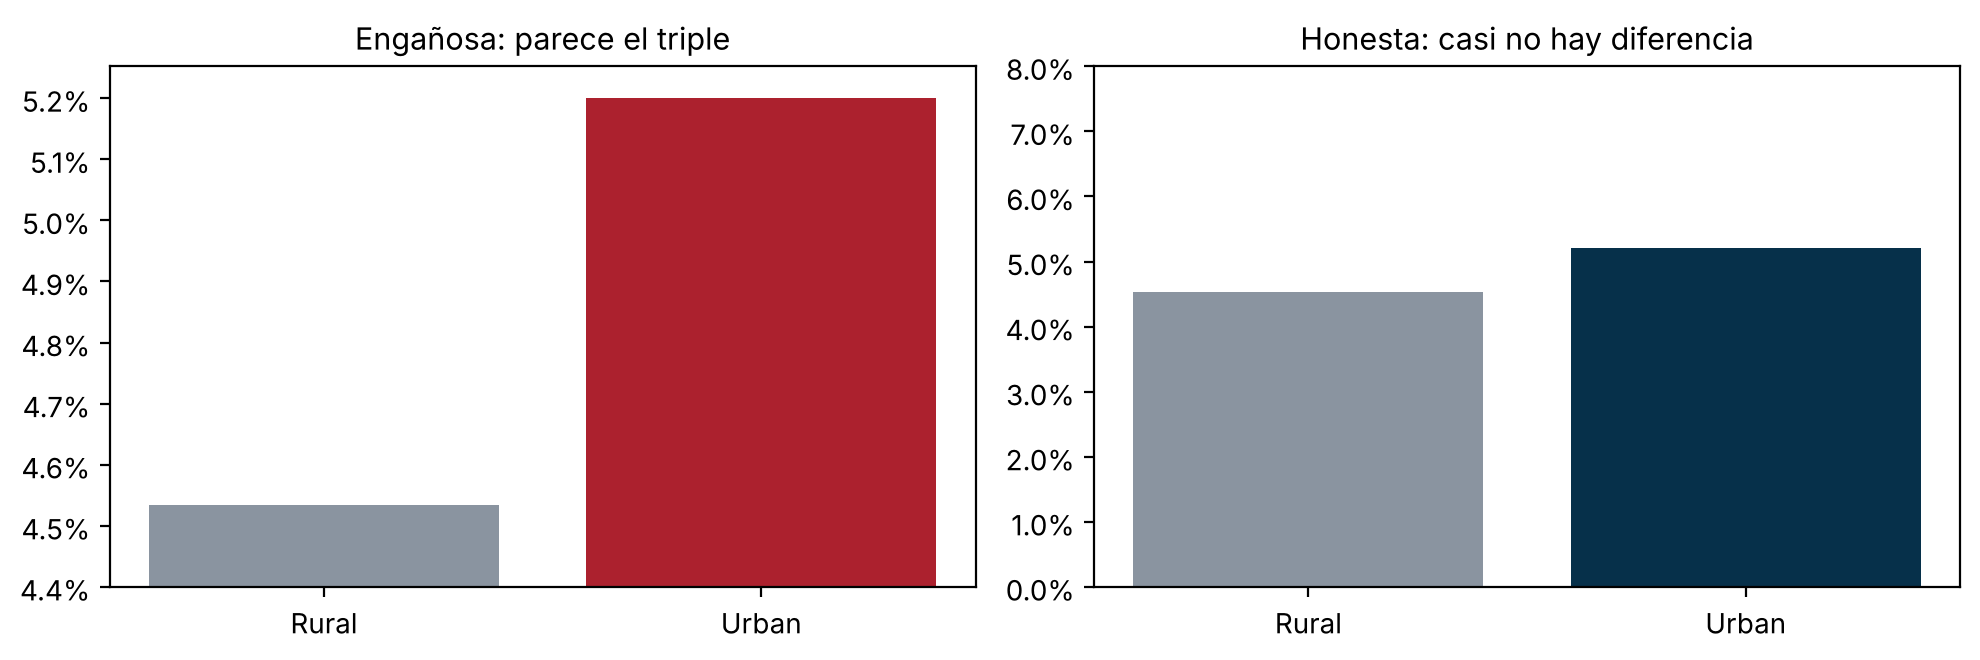

Factor de mentira de Tufte: 34  (una figura honesta tiene un factor cercano a 1)


In [20]:
residencia = datos.groupby("Residence_type")["stroke"].mean()

fig, (mal, bien) = plt.subplots(1, 2, figsize=(10, 3.4))
mal.bar(residencia.index, residencia.values, color=[GRIS, GRANATE])
mal.set_ylim(0.044, residencia.max() * 1.01)
mal.set_title("Engañosa: parece el triple", fontsize=11)
bien.bar(residencia.index, residencia.values, color=[GRIS, AZUL])
bien.set_ylim(0, 0.08)
bien.set_title("Honesta: casi no hay diferencia", fontsize=11)
for eje in (mal, bien):
    eje.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
plt.tight_layout()
plt.show()

real = residencia.max() / residencia.min() - 1
aparente = (residencia.max() - 0.044) / (residencia.min() - 0.044) - 1
print(f"Factor de mentira de Tufte: {aparente / real:.0f}  (una figura honesta tiene un factor cercano a 1)")

Las **barras siempre parten en cero**, porque el ojo compara su longitud. Los gráficos de
puntos y de líneas sí admiten un eje que no parta en cero, porque comparan posición.

### 8.2 El promedio sin tamaño de grupo

In [21]:
por_trabajo = datos.groupby("work_type")["stroke"].agg(["mean", "size"]).sort_values("mean")
por_trabajo.columns = ["tasa", "n"]
por_trabajo["tasa"] = (por_trabajo["tasa"] * 100).round(1)
por_trabajo

,tasa,n
work_type,,
Never_worked,0.0,22
children,0.3,687
Govt_job,5.0,657
Private,5.1,2925
Self-employed,7.9,819


`Never_worked` tiene tasa 0 %, pero son solo 22 personas: con esa cantidad, cero casos es
compatible con una tasa real de hasta un 15 %. Mostrar la tasa sin el tamaño del grupo
invita a una conclusión que los datos no sostienen.

### 8.3 Demasiadas cosas en una figura

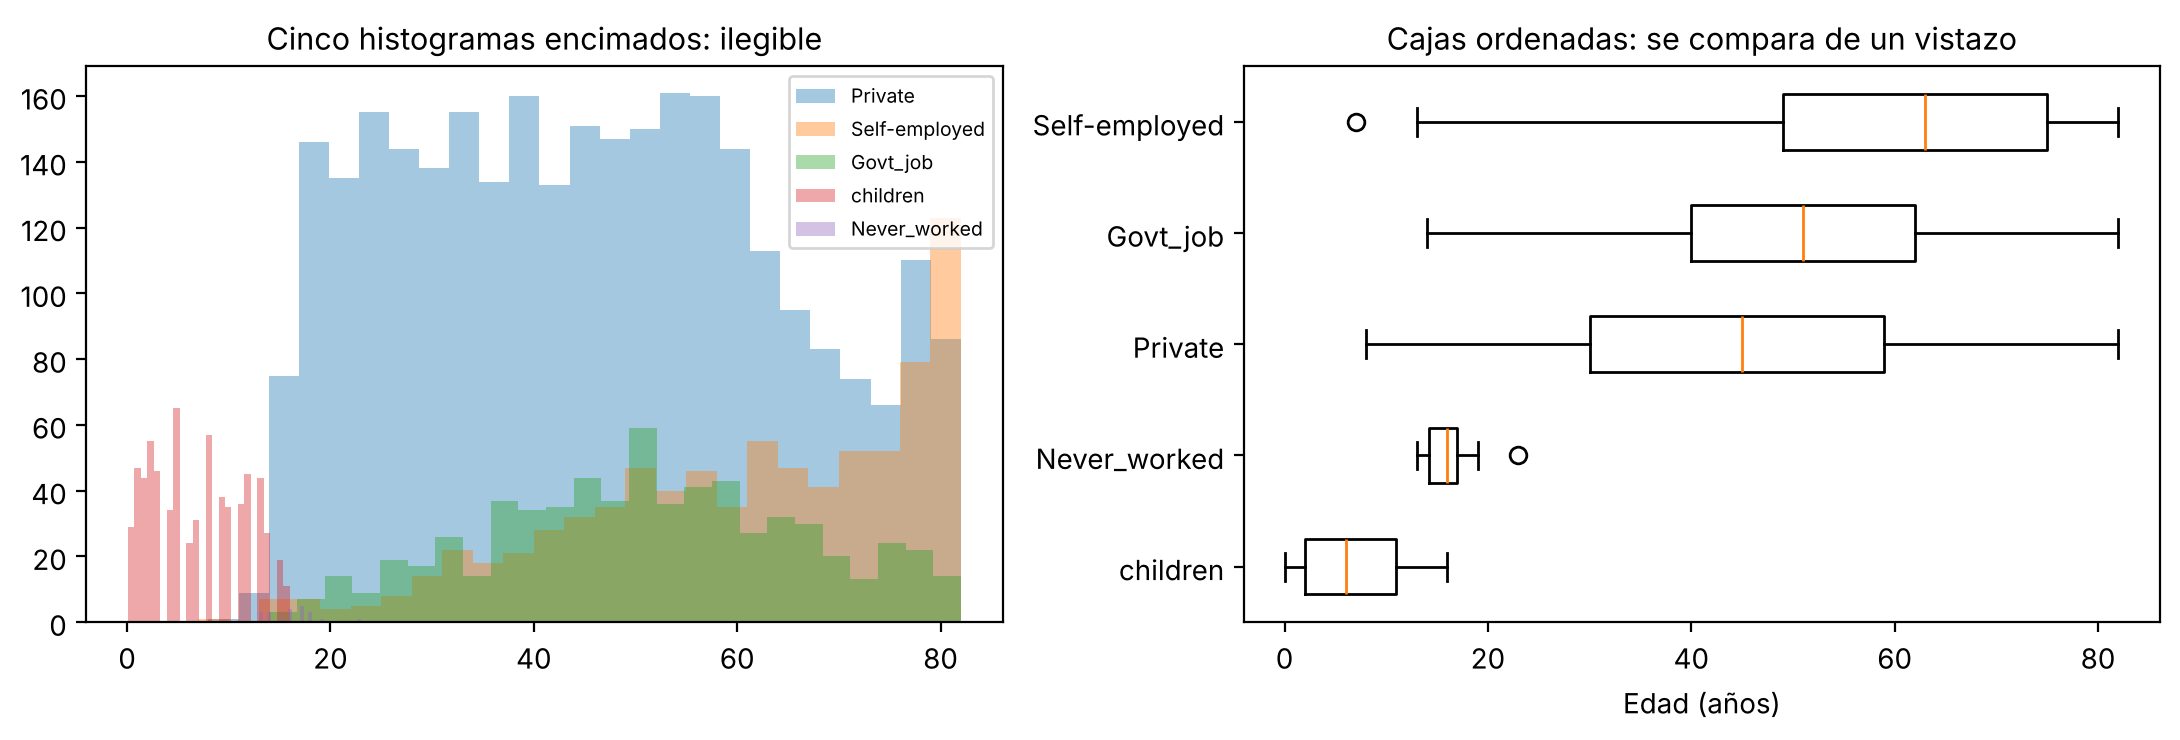

In [22]:
fig, (mal, bien) = plt.subplots(1, 2, figsize=(11, 3.8))
for categoria in datos["work_type"].unique():
    sub = datos[datos["work_type"] == categoria]
    mal.hist(sub["age"], bins=25, alpha=0.4, label=categoria)
mal.legend(fontsize=7)
mal.set_title("Cinco histogramas encimados: ilegible", fontsize=11)

orden = datos.groupby("work_type")["age"].median().sort_values().index
bien.boxplot([datos.loc[datos["work_type"] == c, "age"] for c in orden], tick_labels=orden,
             orientation="horizontal", widths=0.5)
bien.set_xlabel("Edad (años)")
bien.set_title("Cajas ordenadas: se compara de un vistazo", fontsize=11)
plt.tight_layout()
plt.show()

---
## 9. El relato en tres actos

Las figuras no se presentan en el orden en que se hicieron, sino en el orden en que el
lector las necesita. Una estructura que funciona tanto en el informe como en el video:

| Acto | Qué cuenta | Figuras del caso stroke | Tiempo en el video |
|---|---|---|---|
| 1 · El problema | Por qué importa y qué se pregunta | Frecuencia del evento | 1 a 1,5 min |
| 2 · Lo que muestran los datos | Los hallazgos, del más fuerte al más débil | Edad, hipertensión, glucosa | 3 a 4 min |
| 3 · Lo que no se puede afirmar | Limitaciones y asociaciones espurias | Estado civil, faltantes | 1 a 1,5 min |

**Para el video de 5 a 8 minutos.** Cada integrante presenta una parte, cada figura está en
pantalla al menos 20 segundos y el título de la figura se lee en voz alta: es el hallazgo.

---
## 10. Exportar para el informe

Las figuras del informe se guardan como archivo, no como captura de pantalla. Tres
decisiones:

1. **Formato.** PNG para el informe en Word o PDF; SVG si van a editarlas después.
2. **Resolución.** 200 ppp o más para impresión.
3. **Márgenes.** `bbox_inches="tight"` recorta el espacio en blanco sobrante.

In [23]:
CARPETA_FIGURAS = Path("figuras")
CARPETA_FIGURAS.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.bar(tasa.index.astype(str), tasa.values, color=colores)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("Desde los 70 años, más de 1 de cada 6 personas presentó un ACV", loc="left", fontweight="bold")
ruta = CARPETA_FIGURAS / "tasa_por_edad.png"
fig.savefig(ruta, dpi=200, bbox_inches="tight")
plt.close(fig)

# Verificar lo que se guardó, igual que se verificó cada artefacto en las fases anteriores
assert ruta.exists() and ruta.stat().st_size > 0
print(f"Guardada: {ruta}  ({ruta.stat().st_size / 1024:.0f} KB)")

Guardada: figuras/tasa_por_edad.png  (44 KB)


---
## 11. Ejercicios para su proyecto

Resuélvanlos con **su propio conjunto**, partiendo de los artefactos de su Fase 3.

### Ejercicio 1 · Del objetivo a la figura
Completen la tabla con sus objetivos específicos, la pregunta que deriva de cada uno, qué
se compara y qué gráfico corresponde.

In [24]:
# TODO: un registro por objetivo específico de su Fase 1
mi_plan = pd.DataFrame([
    # {"objetivo": "...", "pregunta": "...", "compara": "...", "grafico": "..."},
])
mi_plan

""


### Ejercicio 2 · Su copia interpretable
Lean sus parámetros de la Fase 3 y reviertan el escalamiento de una variable continua.
Verifiquen con `assert` que la media revertida coincide con la media aprendida.

In [25]:
# TODO
# parametros = pd.read_csv("../proyecto-grupoX-mcdi500/data/processed/parametros_f3.csv")
# ...
# assert np.isclose(revertida.mean(), media_aprendida)

### Ejercicio 3 · Los cinco pasos
Tomen una figura de su exploración y llévenla del paso 1 al paso 5 de la sección 4.
Guarden la versión final con 200 ppp.

In [26]:
# TODO

### Ejercicio 4 · Una variable de confusión
Elijan la asociación más fuerte que encontraron y estratifíquenla por la variable que
podría explicarla. Escriban en dos líneas si se mantiene, se reduce o se invierte.

In [27]:
# TODO

### Ejercicio 5 · El guion del video
Escriban el guion en tres actos: qué figura va en cada acto, quién la presenta y cuántos
segundos dura. Comprueben que el total queda entre 5 y 8 minutos.

In [28]:
# TODO
guion = pd.DataFrame([
    # {"acto": 1, "figura": "...", "integrante": "...", "segundos": 60},
])
# print("Duración total:", guion["segundos"].sum() / 60, "minutos")

---
### Referencias

Cleveland, W. S., y McGill, R. (1984). Graphical perception: Theory, experimentation, and
application to the development of graphical methods. *Journal of the American Statistical
Association, 79*(387), 531–554.

Tufte, E. R. (2001). *The visual display of quantitative information* (2.ª ed.). Graphics Press.

Wilke, C. O. (2019). *Fundamentals of data visualization*. O'Reilly Media.